# Taller: Redes neuronales con scikit-learn

### Regresión desde un enfoque de "caja negra"

**Curso:** Minería de Datos

---

## ¿Qué vamos a aprender?

Al terminar este taller vas a poder:

1. Entrenar una **red neuronal** (perceptrón multicapa) para **regresión** y para **clasificación** con `scikit-learn`.
2. Preparar los datos correctamente para que la red funcione (¡esto es más importante de lo que parece!).
3. **Analizar resultados**: métricas, gráficos, errores, variabilidad y qué variables importan.
4. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` y `RandomizedSearchCV`).
5. Aplicar todo lo anterior por tu cuenta en dos problemas nuevos.

## Cómo trabajar con este notebook

- Ejecutá las celdas **en orden** (`Shift + Enter`). Muchas dependen de las anteriores.
- Los bloques con 🤔 **Para pensar** son preguntas para que discutas con tus colegas antes de seguir.
- Al final hay **actividades** para resolver solos/as reutilizando lo que vimos.
- Este notebook está pensado para **Google Colab**: guardá tu propia copia con `Archivo --> Guardar una copia en Drive`.
- No pasa nada si algo falla: ¡equivocarse es parte del proceso! Podés volver a ejecutar cualquier celda.

## Contenido

| Parte | Tema |
|---|---|
| 0 | La idea general: ¿qué es una red neuronal (MLP)? |
| 1 | Preparación del entorno |
| 2 | **Regresión**: predecir el consumo de combustible de autos |
| 3 | **Clasificación**: identificar especies de pingüinos |
| 4 | Resumen y buenas prácticas |
| 5 | **Actividades** para resolver por tu cuenta |

---
# Parte 0 · La idea general

## ¿Qué es un perceptrón multicapa (MLP)?

Un **MLP** (*Multi-Layer Perceptron*) es una red neuronal formada por capas de "neuronas" conectadas entre sí:

```
 Variables de           Capas ocultas            Salida
  entrada          (aquí "ocurre la magia")
                                                   
   x1 ──┐          ┌─ ○ ─┐      ┌─ ○ ─┐
   x2 ──┼────────► │  ○  │ ───► │  ○  │ ───────►  predicción
   x3 ──┤          │  ○  │      └─ ○ ─┘
   ...  ┘          └─ ○ ─┘
```

Cada neurona hace algo muy simple: **combina las entradas con unos pesos, suma y aplica una función de activación** (por ejemplo, ReLU). Al apilar muchas neuronas y varias capas, la red puede aprender relaciones **no lineales** complejas.

El entrenamiento consiste en **ajustar los pesos** para que las predicciones se parezcan cada vez más a los valores reales. Esto se hace de forma iterativa (descenso de gradiente): en cada *época* la red ve los datos, mide su error y corrige un poquito los pesos.

## El enfoque "caja negra"

En este taller **no vamos a programar la red ni a derivar ecuaciones**. Vamos a tratarla como una **caja negra configurable**:

- 1) 📥 Le damos datos (bien preparados).
- 2) 🎛️ Ajustamos unos "botones" (**hiperparámetros**).
- 3) 📊 Evaluamos qué tan bien predice y qué variables influyen.

> Esto **no** significa usarla a ciegas: significa saber **qué botones existen, qué hacen y cómo verificar que el resultado es confiable**.

## 🎛️ Los "botones" principales de `MLPRegressor` / `MLPClassifier`

| Hiperparámetro | ¿Qué controla? | Valores típicos |
|---|---|---|
| `hidden_layer_sizes` | Arquitectura: cuántas capas ocultas y cuántas neuronas en cada una. `(64, 32)` = 2 capas, de 64 y 32 neuronas | `(16,)`, `(64,)`, `(64, 32)` |
| `activation` | Función de activación de las capas ocultas | `"relu"`, `"tanh"`, `"logistic"` |
| `solver` | Algoritmo de optimización | `"adam"` (por defecto), `"lbfgs"` (bueno en datasets chicos), `"sgd"` |
| `alpha` | **Regularización** (penaliza pesos grandes → evita sobreajuste) | `0.0001` a `1` |
| `learning_rate_init` | Tamaño de los "pasos" de aprendizaje (solvers `adam`/`sgd`) | `0.0001` a `0.1` |
| `max_iter` | Máximo de épocas de entrenamiento | `500`, `1000`, `2000` |
| `early_stopping` | Corta el entrenamiento cuando deja de mejorar en validación | `True` / `False` |
| `random_state` | Semilla aleatoria (los pesos iniciales son aleatorios) | cualquier entero |

---
# Parte 1 · Preparación del entorno

Importamos las librerías que vamos a usar. En Google Colab ya vienen instaladas, no hace falta instalar nada.

In [ ]:
# ── Librerías básicas de datos y gráficos ──
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

# ── Utilidades de scikit-learn para preparar datos y validar ──
from sklearn.model_selection import (
    train_test_split, cross_val_score, validation_curve,
    GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning

# ── Los modelos protagonistas: redes neuronales ──
from sklearn.neural_network import MLPRegressor, MLPClassifier

# ── Modelos de referencia (para comparar) ──
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression

# ── Métricas ──
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
)

# ── Para interpretar un modelo "caja negra" ──
from sklearn.inspection import permutation_importance

# ── Distribución para la búsqueda aleatoria de hiperparámetros ──
from scipy.stats import loguniform

# ── Configuración general ──
SEMILLA = 42                       # Fijamos la semilla para que los resultados sean reproducibles
sns.set_theme(style="whitegrid")   # Estilo de gráficos
pd.set_option("display.precision", 3)

# Las redes neuronales lanzan muchos avisos de "convergencia" cuando entrenamos decenas de modelos
# (por ejemplo, en las búsquedas de hiperparámetros). Para no llenar la pantalla los ocultamos,
# pero en la sección 7.1 los vamos a reactivar a propósito para entender qué significan.
warnings.filterwarnings("ignore", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "ignore::sklearn.exceptions.ConvergenceWarning"  # también en procesos paralelos

print("¡Todo listo!")

¡Todo listo!


---
# Parte 2 · Regresión con `MLPRegressor`

## El problema: ¿cuánto consume un auto?

Usaremos el dataset público **Auto MPG** (originalmente del repositorio UCI Machine Learning Repository), disponible en el repositorio de datos de ejemplo de `seaborn`.

Cada fila es un modelo de auto de los años 70-80. Queremos **predecir `mpg`** (millas por galón: a mayor `mpg`, menor consumo) a partir de las características del auto.

> **Variable objetivo (numérica continua):** `mpg` → esto es un problema de **regresión**.

In [ ]:
# Cargamos el dataset directamente desde un repositorio público en GitHub
url_mpg = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df_autos = pd.read_csv(url_mpg)

# Miramos las primeras filas
df_autos.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [ ]:
# Información general: tipos de datos y valores no nulos
df_autos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [ ]:
# Estadísticos descriptivos de las variables numéricas
df_autos.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000,398.000,398.000,392.000,398.000,398.000,398.000
mean,23.515,5.455,193.426,104.469,2970.425,15.568,76.010
std,7.816,1.701,104.270,38.491,846.842,2.758,3.698
min,9.000,3.000,68.000,46.000,1613.000,8.000,70.000
25%,17.500,4.000,104.250,75.000,2223.750,13.825,73.000
50%,23.000,4.000,148.500,93.500,2803.500,15.500,76.000
75%,29.000,8.000,262.000,126.000,3608.000,17.175,79.000
max,46.600,8.000,455.000,230.000,5140.000,24.800,82.000


In [ ]:
# ¿Hay valores faltantes?
print("Valores faltantes por columna:")
print(df_autos.isna().sum())

Valores faltantes por columna:
mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


Vemos que `horsepower` tiene **6 valores faltantes**. Las redes neuronales de `scikit-learn` **no aceptan valores faltantes**, así que más adelante los vamos a imputar (rellenar) dentro del propio flujo de trabajo.

Miremos algunos gráficos para entender los datos:

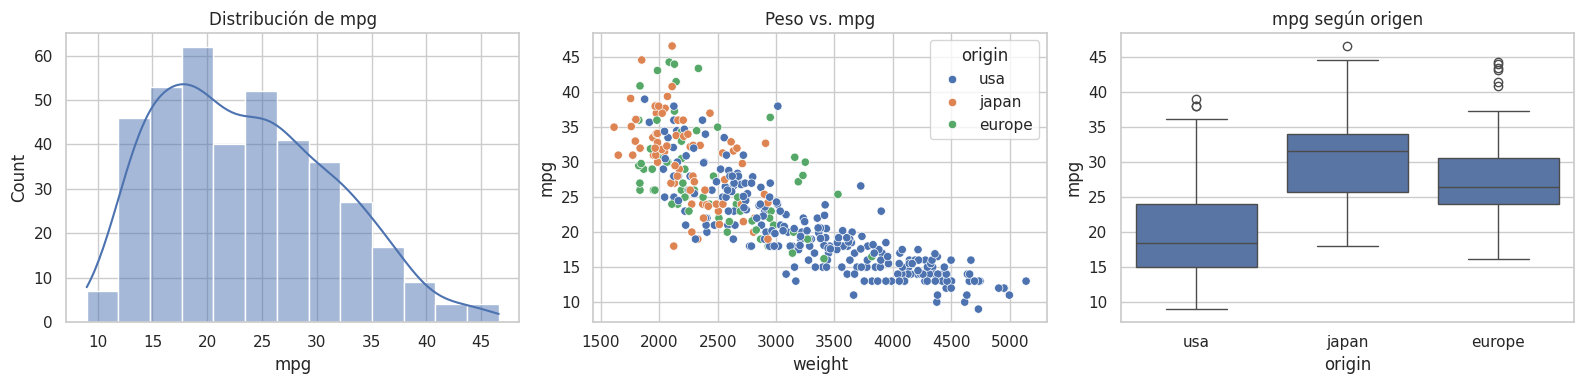

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))

# 1) Distribución de la variable objetivo
sns.histplot(df_autos["mpg"], kde=True, ax=ejes[0])
ejes[0].set_title("Distribución de mpg")

# 2) Relación entre peso y consumo
sns.scatterplot(data=df_autos, x="weight", y="mpg", hue="origin", ax=ejes[1])
ejes[1].set_title("Peso vs. mpg")

# 3) mpg según origen del auto
sns.boxplot(data=df_autos, x="origin", y="mpg", ax=ejes[2])
ejes[2].set_title("mpg según origen")

plt.tight_layout()
plt.show()

### 🤔 Para pensar
- ¿Qué relación observás entre el peso del auto y su consumo? ¿Parece lineal?

Puedo observar en el grafico que a medida que aumenta el peso del auto las millas por galon disminuyen, esto se debe a que el auto al pesar mas, requiere mas fuerza del motor para moverse, por ende mas consumo.
Hay una clara relacion linear descendiente, ya que al aumentar el valor de la variable independiente (x = weight) el valor de la variable dependiente (y = mpg) disminuye.

- ¿Crees que el origen del auto aporta información útil?

Totalmente, en el segundo grafico se puede observar como claramente los modelos japoneses y europeos tienden a ser mas livianos, por ende a tener una mejor eficiencia a la hora del consumo, algo que confirma el grafico 3, ya que podemos ver como los autos japoneses y europeos tienden a hacer mas millas por galon.

## Paso 1: separar variables y dividir en entrenamiento / prueba

- **X**: variables predictoras (características del auto). Quitamos `name` porque es un identificador, no una característica útil.
- **y**: variable objetivo (`mpg`).

Dividimos en:
- **Entrenamiento (80 %)**: con estos datos la red aprende.
- **Prueba (20 %)**: los guardamos "bajo llave" para evaluar al final. ⚠️ **No se tocan** hasta la evaluación final: simulan datos nuevos que el modelo nunca vio.

In [ ]:
# Separamos predictoras (X) y objetivo (y)
X = df_autos.drop(columns=["mpg", "name"])
y = df_autos["mpg"]

# Dividimos en entrenamiento y prueba
X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA
)

print(f"Entrenamiento: {X_ent.shape[0]} autos")
print(f"Prueba:        {X_prueba.shape[0]} autos")

Entrenamiento: 318 autos
Prueba:        80 autos


## Paso 2. Modelos de referencia (*baselines*)

Antes de entrenar una red neuronal, siempre conviene tener **modelos simples para comparar**. Si la red no le gana a un modelo simple, no vale la pena la complejidad.

Vamos a usar dos:
- **Dummy**: predice siempre el promedio de `mpg` (el modelo más "tonto" posible).
- **Regresión lineal**: un modelo simple y muy usado.

Primero definimos **cómo preparar los datos** (el "preprocesador") y una función para evaluar modelos.

### Preprocesamiento: ¡clave para las redes neuronales!

Las redes neuronales son **muy sensibles a la escala** de las variables. Por ejemplo, `weight` está en miles (≈ 3000) y `cylinders` entre 3 y 8. Si no las escalamos, la red aprende mal.

Necesitamos:
1. **Imputar** valores faltantes (con la mediana en variables numéricas).
2. **Estandarizar** las numéricas (`StandardScaler`: media 0 y desvío 1).
3. **Codificar** las categóricas como columnas 0/1 (`OneHotEncoder`), porque la red solo entiende números.

Todo esto lo empaquetamos en un `ColumnTransformer`. Lo bueno: al meterlo dentro de un `Pipeline`, el preprocesamiento se **ajusta solo con los datos de entrenamiento** y se aplica automáticamente a los de prueba (evitando "filtrar" información de prueba, lo que se llama *data leakage*).

In [ ]:
# Separamos las columnas según su tipo
cols_num = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
cols_cat = ["origin"]

# Preprocesador: qué hacerle a cada grupo de columnas
preprocesador_reg = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),   # rellena faltantes con la mediana
        ("escalar", StandardScaler())                    # media 0, desvío 1
    ]), cols_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cols_cat)  # categorías -> columnas 0/1
])

preprocesador_reg

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['cylinders', 'displacement', 'horsepower',
                                  'weight', 'acceleration', 'model_year']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['origin'])])

In [ ]:
# Función para evaluar un modelo de regresión de forma ordenada
def evaluar_regresion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "RMSE_entrenamiento": root_mean_squared_error(y_ent, pred_ent),
        "RMSE_prueba": root_mean_squared_error(y_prueba, pred_prueba),
        "MAE_prueba": mean_absolute_error(y_prueba, pred_prueba),
        "R2_prueba": r2_score(y_prueba, pred_prueba),
    }

# Aquí iremos guardando los resultados de cada modelo para compararlos al final
resultados_reg = []

In [ ]:
# Baseline 1: predice siempre el promedio
modelo_dummy = DummyRegressor(strategy="mean")
modelo_dummy.fit(X_ent[cols_num], y_ent)
resultados_reg.append(evaluar_regresion(modelo_dummy, X_ent[cols_num], y_ent, X_prueba[cols_num], y_prueba, "Dummy (promedio)"))

# Baseline 2: regresión lineal (dentro de un Pipeline con el mismo preprocesador)
modelo_lineal = Pipeline([
    ("prep", preprocesador_reg),
    ("modelo", LinearRegression())
])
modelo_lineal.fit(X_ent, y_ent)
resultados_reg.append(evaluar_regresion(modelo_lineal, X_ent, y_ent, X_prueba, y_prueba, "Regresión lineal"))

pd.DataFrame(resultados_reg)

,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),7.918,7.347,5.955,-0.004
1,Regresión lineal,3.370,2.888,2.288,0.845


### 📏 ¿Cómo leer las métricas de regresión?

- **RMSE** (raíz del error cuadrático medio): error típico de la predicción, **en las mismas unidades que `mpg`**. Penaliza más los errores grandes. *Menor es mejor.*
- **MAE** (error absoluto medio): promedio de cuánto nos equivocamos, en unidades de `mpg`. *Menor es mejor.*
- **R²**: proporción de la variabilidad de `y` que el modelo explica. 1 = perfecto, 0 = igual que predecir el promedio. *Mayor es mejor.*

Fijate también en la diferencia entre **RMSE de entrenamiento y de prueba**: si en entrenamiento es mucho menor, hay señales de **sobreajuste** (el modelo "memorizó" en lugar de aprender).

## Paso 3 ¿Por qué hay que escalar? Una demostración

Veamos con nuestros propios ojos qué pasa si entrenamos la red **sin estandarizar** las variables (solo imputamos los faltantes) y lo comparamos con la red **con escalado**.

Como los pesos iniciales son aleatorios, repetimos el experimento con **5 semillas distintas** (una sola corrida podría engañarnos).

In [ ]:
r2_sin_escalar, r2_con_escalado = [], []

for semilla in range(5):
    # (a) Red SIN escalar: solo variables numéricas, imputadas
    sin_escalar = Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=semilla))
    ]).fit(X_ent[cols_num], y_ent)
    r2_sin_escalar.append(r2_score(y_prueba, sin_escalar.predict(X_prueba[cols_num])))

    # (b) Red CON escalado: usamos nuestro preprocesador completo
    con_escalado = Pipeline([
        ("prep", preprocesador_reg),
        ("mlp", MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=semilla))
    ]).fit(X_ent, y_ent)
    r2_con_escalado.append(r2_score(y_prueba, con_escalado.predict(X_prueba)))

demo_escalado = pd.DataFrame({
    "semilla": range(5),
    "R2 sin escalar": r2_sin_escalar,
    "R2 con escalado": r2_con_escalado
})
demo_escalado

,semilla,R2 sin escalar,R2 con escalado
0,0,-3.391,0.898
1,1,0.796,0.903
2,2,-1.308,0.905
3,3,0.891,0.912
4,4,-72.231,0.909


> 💡 **Lección:** sin escalar, la red puede **divergir** (R² muy negativo: ¡peor que predecir siempre el promedio!) o depender de la suerte de la semilla. Con variables estandarizadas, el entrenamiento es **estable** y los resultados son buenos y consistentes. Por eso el escalado es **obligatorio** en redes neuronales.

## Paso 4: nuestra primera red neuronal para regresión

Armamos un `Pipeline` con dos pasos:
1. `prep`: el preprocesador que definimos.
2. `mlp`: la red neuronal `MLPRegressor`.

Usamos `hidden_layer_sizes=(64, 32)`: dos capas ocultas, la primera con 64 neuronas y la segunda con 32.

In [ ]:
# Definimos la red neuronal dentro de un Pipeline
mlp_reg = Pipeline([
    ("prep", preprocesador_reg),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=(64, 32),   # 2 capas ocultas: 64 y 32 neuronas
        activation="relu",             # función de activación
        max_iter=2000,                 # máximo de épocas
        random_state=SEMILLA           # semilla para reproducibilidad
    ))
])

# Entrenamos ("fit") con los datos de entrenamiento
mlp_reg.fit(X_ent, y_ent)

# ¿Cuántas épocas usó realmente la red? (si es igual a max_iter, llegó al límite)
print("Épocas realizadas:", mlp_reg.named_steps["mlp"].n_iter_)

# Evaluamos y guardamos resultados
resultados_reg.append(evaluar_regresion(mlp_reg, X_ent, y_ent, X_prueba, y_prueba, "MLP inicial (64,32)"))
pd.DataFrame(resultados_reg)

Épocas realizadas: 2000


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Dummy (promedio),7.918,7.347,5.955,-0.004
1,Regresión lineal,3.370,2.888,2.288,0.845
2,"MLP inicial (64,32)",1.745,2.427,1.763,0.890


## Paso 5 · Analizar los resultados

Los números solos no cuentan toda la historia. Miremos **tres gráficos** muy útiles:

1. **Curva de pérdida**: cómo baja el error durante el entrenamiento. Debería descender y estabilizarse.
2. **Real vs. predicho**: si el modelo fuera perfecto, todos los puntos estarían sobre la diagonal.
3. **Residuos** (real − predicho): deberían estar centrados en 0 y sin patrones marcados.

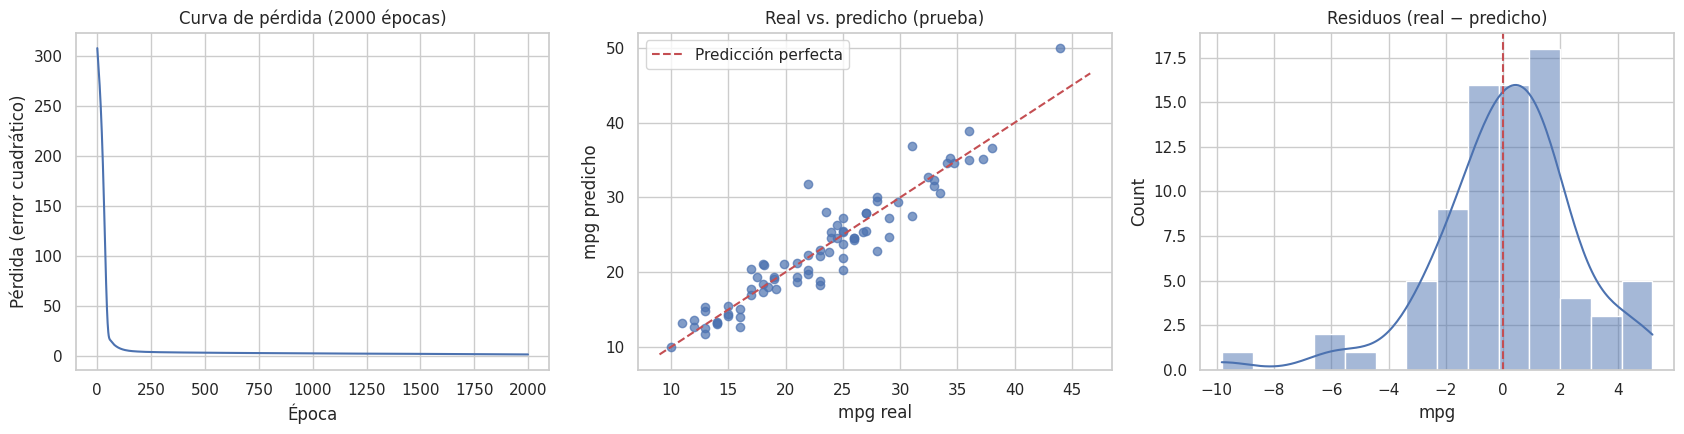

In [ ]:
# Obtenemos el objeto MLP que está dentro del Pipeline
red = mlp_reg.named_steps["mlp"]
pred_prueba = mlp_reg.predict(X_prueba)
residuos = y_prueba - pred_prueba

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Curva de pérdida durante el entrenamiento
ejes[0].plot(red.loss_curve_)
ejes[0].set_title(f"Curva de pérdida ({red.n_iter_} épocas)")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida (error cuadrático)")

# 2) Real vs predicho
ejes[1].scatter(y_prueba, pred_prueba, alpha=0.7)
lim = [y.min(), y.max()]
ejes[1].plot(lim, lim, "r--", label="Predicción perfecta")
ejes[1].set_title("Real vs. predicho (prueba)")
ejes[1].set_xlabel("mpg real")
ejes[1].set_ylabel("mpg predicho")
ejes[1].legend()

# 3) Histograma de residuos
sns.histplot(residuos, kde=True, ax=ejes[2])
ejes[2].axvline(0, color="r", linestyle="--")
ejes[2].set_title("Residuos (real − predicho)")

plt.tight_layout()
plt.show()

### 🤔 Para pensar
- ¿La curva de pérdida se estabilizó, o el entrenamiento terminó "a la fuerza" por `max_iter`? (Mirá el número de épocas en el título del gráfico.)

Con epocas nos referimos a las pasadas que realizan los datos sobre las capas de las redes neuronales y como se van ajustando de a poco los pesos de cada conexion de las neuronas que toman la decision de que valor predecir, en el grafico, podemos ver como a partir de la pasada 100 (aproximadamente) el modelo no realizo ningun cambio abrupto y se comenzo a estabilizar.
Aunque el modelo aprendio lo suficiente en las primeras pasadas y la perdida bajo, no fue lo suficiente para que scikit-learn cortara solo, por ende el entrenamiento termino por el max_iter definido

- ¿En qué rango de `mpg` se equivoca más el modelo?

En el segundo grafico se puede observar que el modelo se equivoca mas en un rango de 20 a 30 mpg, donde los puntos se definen de la siguiente manera, mpg real (define el valor de x) y mpg predicho (define el valor de y).
La linea roja se refiere a una prediccion perfecta, se puede observar que los puntos son mas dispersos en relacion a la linea roja a partir de las 20 millas por galon.   

## Paso 6 · Un detalle importante: la aleatoriedad

Los **pesos iniciales** de la red se eligen al azar. Eso significa que **dos entrenamientos con distinta semilla pueden dar resultados distintos**, aunque los datos y la configuración sean idénticos.

Veamos cuánto varía el resultado entrenando la misma red con 10 semillas diferentes:

R² en prueba con 10 semillas distintas:
[0.873 0.891 0.895 0.902 0.89  0.886 0.891 0.879 0.878 0.882]

Promedio: 0.887  |  Desvío: 0.008
Mínimo:   0.873  |  Máximo: 0.902


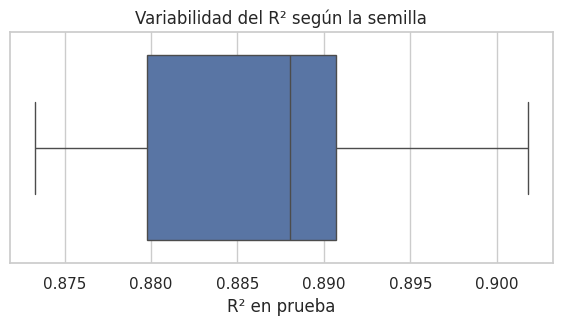

In [ ]:
r2_por_semilla = []

for semilla in range(10):
    modelo = clone(mlp_reg)                        # copia "limpia" del pipeline
    modelo.set_params(mlp__random_state=semilla)   # cambiamos solo la semilla de la red
    modelo.fit(X_ent, y_ent)
    r2_por_semilla.append(r2_score(y_prueba, modelo.predict(X_prueba)))

print("R² en prueba con 10 semillas distintas:")
print(np.round(r2_por_semilla, 3))
print(f"\nPromedio: {np.mean(r2_por_semilla):.3f}  |  Desvío: {np.std(r2_por_semilla):.3f}")
print(f"Mínimo:   {np.min(r2_por_semilla):.3f}  |  Máximo: {np.max(r2_por_semilla):.3f}")

plt.figure(figsize=(7, 3))
sns.boxplot(x=r2_por_semilla)
plt.title("Variabilidad del R² según la semilla")
plt.xlabel("R² en prueba")
plt.show()

> 💡 **Lección:** una diferencia pequeña entre dos configuraciones puede ser **puro azar**. Por eso es importante usar **validación cruzada** (que promedia varias evaluaciones) para comparar modelos, en lugar de fiarnos de una sola corrida.

## Paso 7 · Explorando hiperparámetros "a mano"

Antes de automatizar la búsqueda, entendamos el efecto de algunos "botones".

### 7.1 · `max_iter`: ¿y si cortamos el entrenamiento muy pronto?

Si la red no tiene tiempo suficiente para converger, `scikit-learn` nos avisa con un `ConvergenceWarning`:

In [ ]:
# Entrenamos con solo 20 épocas: ¡muy poco!
mlp_corto = clone(mlp_reg)
mlp_corto.set_params(mlp__max_iter=20)

# Reactivamos (solo dentro de este bloque) los avisos de convergencia que habíamos ocultado
with warnings.catch_warnings():
    warnings.simplefilter("always", ConvergenceWarning)
    mlp_corto.fit(X_ent, y_ent)   # <- verás una advertencia de convergencia

print(f"R² en prueba con 20 épocas:   {r2_score(y_prueba, mlp_corto.predict(X_prueba)):.3f}")
print(f"R² en prueba con 2000 épocas: {r2_score(y_prueba, mlp_reg.predict(X_prueba)):.3f}")

R² en prueba con 20 épocas:   -7.037
R² en prueba con 2000 épocas: 0.890


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (20) reached and the optimization hasn't converged yet.
  warnings.warn(


> ⚠️ **Si ves un `ConvergenceWarning`**: la red no terminó de aprender. Aumentá `max_iter`, o revisá que las variables estén escaladas.
>
> Al inicio del notebook ocultamos estos avisos para no llenar la pantalla, pero **no dejes de vigilar** cuántas épocas usa tu red: se consulta con `red.n_iter_` (si es igual a `max_iter`, el entrenamiento terminó por el límite y no porque convergió).

### 7.2 · `hidden_layer_sizes`: ¿cuántas neuronas necesitamos?

Usaremos una **curva de validación**: entrenamos redes de una capa con distinta cantidad de neuronas y medimos el R² tanto en entrenamiento como en validación cruzada (5 particiones del conjunto de entrenamiento).

- Pocas neuronas → el modelo es demasiado simple (**subajuste**).
- Muchas neuronas → puede volverse demasiado complejo (**sobreajuste**).

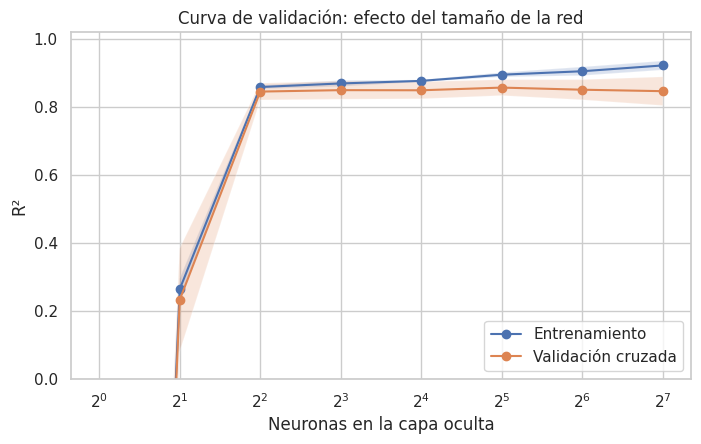

In [ ]:
# Probamos redes de una capa con distinta cantidad de neuronas
neuronas = [1, 2, 4, 8, 16, 32, 64, 128]
arquitecturas = [(n,) for n in neuronas]

puntaje_ent, puntaje_val = validation_curve(
    mlp_reg, X_ent, y_ent,
    param_name="mlp__hidden_layer_sizes",
    param_range=arquitecturas,
    cv=5, scoring="r2", n_jobs=-1
)

# Graficamos promedio ± desvío
plt.figure(figsize=(8, 4.5))
for puntajes, etiqueta in [(puntaje_ent, "Entrenamiento"), (puntaje_val, "Validación cruzada")]:
    media, desvio = puntajes.mean(axis=1), puntajes.std(axis=1)
    plt.plot(neuronas, media, marker="o", label=etiqueta)
    plt.fill_between(neuronas, media - desvio, media + desvio, alpha=0.2)

plt.xscale("log", base=2)
plt.xlabel("Neuronas en la capa oculta")
plt.ylabel("R²")
plt.title("Curva de validación: efecto del tamaño de la red")
plt.ylim(0, 1.02)
plt.legend()
plt.show()

### 🤔 Para pensar
- ¿A partir de cuántas neuronas deja de mejorar el R² de validación?

El R² de validación deja de mejorar a partir de las 4 neuronas en la capa oculta, ya que en el grafico podemos notar que a partir de neuronas en la capa oculta = 2², los valores dejan de aumentar y se mantienen practicamente constantes a medida de que aumenta 2ⁿ

- ¿Hay una brecha entre la curva de entrenamiento y la de validación? ¿Qué nos dice eso?

Si, a partir de 2³ podemos observar como comienza a generarse una brecha entre la curva de entrenamiento y la validacion cruzada, esto indica que es posible que a medida de que sumamos neuronas a la capa tiende a sobreajustarse el modelo, osea que el modelo mejora con los datos que ya vio pero no con los nuevos.

## Paso 8: búsqueda automática de hiperparámetros: `GridSearchCV`

Probar combinaciones a mano es lento y poco riguroso. `GridSearchCV` hace esto por nosotros:

1. Definimos una **grilla** con los valores a probar para cada hiperparámetro.
2. Para **cada combinación**, entrena y evalúa con **validación cruzada** (aquí, 5 particiones).
3. Nos dice cuál fue la mejor y **reentrena** el mejor modelo con todo el conjunto de entrenamiento.

> ⚠️ Toda la búsqueda usa **solo los datos de entrenamiento**. El conjunto de prueba sigue intacto.

Nota: dentro de un `Pipeline`, los hiperparámetros se nombran como `paso__parametro` (con **doble guion bajo**), por ejemplo `mlp__alpha`.

Nuestra grilla tiene 3 × 3 × 2 = **18 combinaciones**, y con 5 particiones son 90 entrenamientos. Puede tardar 1-2 minutos. ☕

In [ ]:
# Grilla de hiperparámetros a explorar
grilla_reg = {
    "mlp__hidden_layer_sizes": [(16,), (64,), (64, 32)],   # arquitecturas
    "mlp__alpha": [0.0001, 0.01, 1.0],                     # regularización
    "mlp__learning_rate_init": [0.001, 0.01],              # tamaño de paso
}

busqueda_reg = GridSearchCV(
    estimator=mlp_reg,
    param_grid=grilla_reg,
    cv=5,                                     # validación cruzada de 5 particiones
    scoring="neg_root_mean_squared_error",    # sklearn maximiza: usamos -RMSE
    n_jobs=-1,                                # usa todos los núcleos disponibles
    verbose=1
)

busqueda_reg.fit(X_ent, y_ent)

print("\nMejores hiperparámetros:")
print(busqueda_reg.best_params_)
print(f"\nMejor RMSE en validación cruzada: {-busqueda_reg.best_score_:.3f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Mejores hiperparámetros:
{'mlp__alpha': 1.0, 'mlp__hidden_layer_sizes': (64,), 'mlp__learning_rate_init': 0.01}

Mejor RMSE en validación cruzada: 2.877


### Mirando todos los resultados de la búsqueda

`cv_results_` guarda lo que pasó con **cada** combinación. Conviene convertirlo en una tabla y ordenarlo. Prestá atención a la columna `std_test_score`: si el desvío es grande comparado con las diferencias entre modelos, esas diferencias **no son concluyentes**.

In [ ]:
res = pd.DataFrame(busqueda_reg.cv_results_)
res["RMSE_cv"] = -res["mean_test_score"]     # volvemos a un RMSE positivo

columnas = ["param_mlp__hidden_layer_sizes", "param_mlp__alpha", "param_mlp__learning_rate_init",
            "RMSE_cv", "std_test_score", "rank_test_score"]

res.sort_values("rank_test_score")[columnas].head(8)

,param_mlp__hidden_layer_sizes,param_mlp__alpha,param_mlp__learning_rate_init,RMSE_cv,std_test_score,rank_test_score
15,"(64,)",1.000e+00,0.010,2.877,0.330,1
16,"(64, 32)",1.000e+00,0.001,2.953,0.228,2
10,"(64, 32)",1.000e-02,0.001,2.973,0.267,3
4,"(64, 32)",1.000e-04,0.001,2.974,0.239,4
17,"(64, 32)",1.000e+00,0.010,2.982,0.335,5
14,"(64,)",1.000e+00,0.001,3.011,0.344,6
9,"(64,)",1.000e-02,0.010,3.013,0.257,7
12,"(16,)",1.000e+00,0.001,3.020,0.303,8


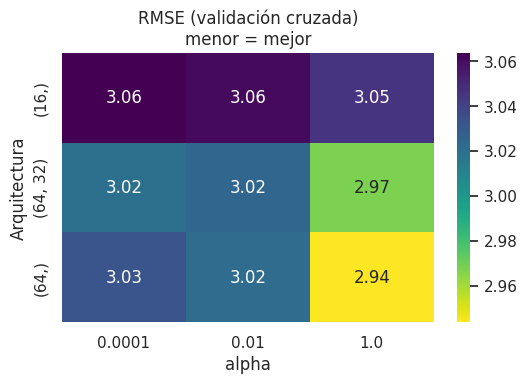

In [ ]:
# Visualizamos: RMSE promedio según arquitectura y alpha (promediando sobre learning rate)
res["arquitectura"] = res["param_mlp__hidden_layer_sizes"].astype(str)
tabla = res.pivot_table(index="arquitectura", columns="param_mlp__alpha", values="RMSE_cv", aggfunc="mean")

plt.figure(figsize=(6, 3.5))
sns.heatmap(tabla, annot=True, fmt=".2f", cmap="viridis_r")
plt.title("RMSE (validación cruzada)\nmenor = mejor")
plt.xlabel("alpha")
plt.ylabel("Arquitectura")
plt.show()

## Paso 9 · Evaluación final en el conjunto de prueba

Ahora sí, usamos por **única vez** el conjunto de prueba para evaluar el mejor modelo encontrado. Lo tenemos en `busqueda_reg.best_estimator_` (ya reentrenado con todo el conjunto de entrenamiento).

In [ ]:
mejor_reg = busqueda_reg.best_estimator_

resultados_reg.append(evaluar_regresion(mejor_reg, X_ent, y_ent, X_prueba, y_prueba, "MLP optimizado (GridSearch)"))

tabla_final_reg = pd.DataFrame(resultados_reg).set_index("modelo")
tabla_final_reg

,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
modelo,,,,
Dummy (promedio),7.918,7.347,5.955,-0.004
Regresión lineal,3.370,2.888,2.288,0.845
"MLP inicial (64,32)",1.745,2.427,1.763,0.890
MLP optimizado (GridSearch),2.176,2.404,1.796,0.893


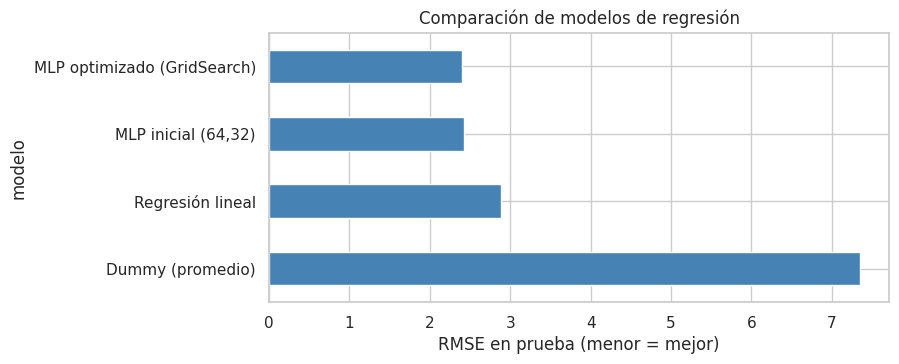

In [ ]:
# Comparamos gráficamente el RMSE en prueba de todos los modelos
tabla_final_reg["RMSE_prueba"].plot(kind="barh", figsize=(8, 3.5), color="steelblue")
plt.xlabel("RMSE en prueba (menor = mejor)")
plt.title("Comparación de modelos de regresión")
plt.show()

## Paso 10. Abriendo un poco la caja negra: importancia por permutación

Aunque la red es una "caja negra", podemos preguntarle **qué variables le importan**. La **importancia por permutación** funciona así:

1. Tomamos los datos de prueba y **mezclamos al azar** los valores de **una** variable.
2. Medimos cuánto **empeora** el error del modelo.
3. Si empeora mucho → esa variable era **importante**. Si casi no cambia → no aportaba.

Como usamos el `Pipeline` completo, la importancia se calcula sobre las **variables originales** (por ejemplo `origin` completo, no cada columna 0/1).

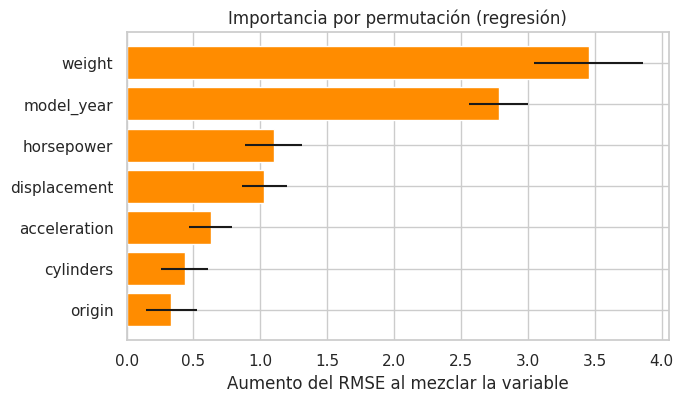

In [ ]:
imp = permutation_importance(
    mejor_reg, X_prueba, y_prueba,
    n_repeats=20,                              # repetimos el mezclado 20 veces
    scoring="neg_root_mean_squared_error",
    random_state=SEMILLA
)

importancias = pd.DataFrame({
    "variable": X_prueba.columns,
    "aumento_RMSE": imp.importances_mean,      # cuánto empeora el RMSE al mezclar la variable
    "desvio": imp.importances_std
}).sort_values("aumento_RMSE")

plt.figure(figsize=(7, 4))
plt.barh(importancias["variable"], importancias["aumento_RMSE"], xerr=importancias["desvio"], color="darkorange")
plt.xlabel("Aumento del RMSE al mezclar la variable")
plt.title("Importancia por permutación (regresión)")
plt.show()

### Usando el modelo en un caso nuevo

Una vez entrenado, el `Pipeline` funciona como una función: le pasamos un auto **con las columnas originales** y devuelve la predicción (el preprocesamiento se hace solo).

In [ ]:
# Un auto hipotético que no está en el dataset
auto_nuevo = pd.DataFrame([{
    "cylinders": 4, "displacement": 120, "horsepower": 95,
    "weight": 2300, "acceleration": 15, "model_year": 80, "origin": "japan"
}])

print(f"Consumo predicho: {mejor_reg.predict(auto_nuevo)[0]:.1f} mpg")

Consumo predicho: 30.6 mpg


---
# Parte 4. Resumen y buenas prácticas

## La receta que usamos (sirve para regresión y clasificación)

1. **Explorar** los datos (tipos, faltantes, distribuciones).
2. **Dividir** en entrenamiento y prueba (con `stratify` si es clasificación).
3. **Preprocesar dentro de un `Pipeline`**: imputar → escalar numéricas → codificar categóricas.
4. Entrenar **modelos de referencia** (Dummy, lineal/logístico) para tener con qué comparar.
5. Entrenar la **red neuronal** y **analizar resultados** (métricas, gráficos, errores).
6. **Ajustar hiperparámetros** con validación cruzada (`GridSearchCV` / `RandomizedSearchCV`), usando **solo** el conjunto de entrenamiento.
7. **Evaluar una sola vez** en el conjunto de prueba.
8. **Interpretar** con importancia por permutación y **reportar** con honestidad (¡incluida la variabilidad!).

## ✅ Checklist rápido

| Situación | Qué hacer |
|---|---|
| `ConvergenceWarning` (o `n_iter_` igual a `max_iter`) | Aumentar `max_iter`, verificar que las variables estén escaladas, probar otro `solver` |
| Rendimiento muy bueno en entrenamiento y malo en prueba (sobreajuste) | Aumentar `alpha`, reducir neuronas, usar `early_stopping=True`, conseguir más datos |
| Rendimiento malo en ambos (subajuste) | Más neuronas/capas, más épocas, mejores variables |
| Resultados que cambian mucho entre corridas | Fijar `random_state`, comparar con validación cruzada, repetir con varias semillas |
| Dataset muy pequeño | Probar `solver="lbfgs"` |
| Clases desbalanceadas | No confiar solo en accuracy: mirar F1 macro, recall por clase y matriz de confusión |

## ⚖️ Ventajas y limitaciones de los MLP

** Ventajas:** capturan relaciones no lineales e interacciones complejas sin que las especifiquemos.

**Limitaciones:** son sensibles a la escala, tienen muchos hiperparámetros, son poco interpretables y suelen no superar a otros métodos (como bosques aleatorios o *gradient boosting*) en datos tabulares pequeños. ¡Siempre comparalos!

> `scikit-learn` es ideal para aprender y para problemas tabulares pequeños o medianos. Para redes profundas, imágenes, texto o mucho volumen de datos se usan librerías como **PyTorch** o **TensorFlow/Keras**.

---
# Parte 5 - Actividades

Ahora es tu turno. **Reutilizá el código de las partes anteriores** (copiar, pegar y adaptar es totalmente válido). Cada actividad indica qué parte del taller te sirve de guía.

> 💡 En las celdas de código encontrarás pistas como comentarios. Las celdas de texto "**Tu respuesta:**" son para que escribas tus conclusiones (doble clic para editar).

## Actividad 1. Regresión: predecir el precio de diamantes

**Dataset:** `diamonds` (público, repositorio de datos de `seaborn`). Cada fila es un diamante con su precio en dólares y características como peso (`carat`), calidad de corte (`cut`), color (`color`), claridad (`clarity`) y dimensiones (`x`, `y`, `z`).

**Objetivo:** predecir `price` con una red neuronal y compararla con modelos de referencia.

**Te sirve de guía:** Parte 2 (Regresión).

Para que los entrenamientos no tarden demasiado, trabajaremos con una **muestra de 3000 diamantes**.

In [ ]:
# Cargamos el dataset y tomamos una muestra de 3000 filas
url_diamantes = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv"
df_diam = pd.read_csv(url_diamantes).sample(n=3000, random_state=SEMILLA).reset_index(drop=True)

df_diam.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
1,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
2,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
3,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
4,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61


**1.1 · Exploración.** Averiguá: ¿cuántas variables numéricas y categóricas hay? ¿Hay valores faltantes? Graficá la distribución de `price` y la relación entre `carat` y `price`. ¿Notás algo particular en la distribución del precio?

In [ ]:
# Tu código aquí
# Pista: df_diam.info(), df_diam.describe(), sns.histplot(...), sns.scatterplot(...)
df_diam.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    3000 non-null   float64
 1   cut      3000 non-null   object 
 2   color    3000 non-null   object 
 3   clarity  3000 non-null   object 
 4   depth    3000 non-null   float64
 5   table    3000 non-null   float64
 6   price    3000 non-null   int64  
 7   x        3000 non-null   float64
 8   y        3000 non-null   float64
 9   z        3000 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 234.5+ KB


Al observar los tipos de datos que contiene cada columna puedo identificar que en el dataset existen 7 variables numericas:
`carat`, `depth`, `table`, `price`, `x`, `y`, `z`.

Y 3 variables categoricas: `cut`, `color`, `clarity`.

Con .info, tambien llego a la conclusion que en la muestra de los 3000 registros que tomamos para este entrenamiento, no existen valores faltantes en ninguna de las columnas.

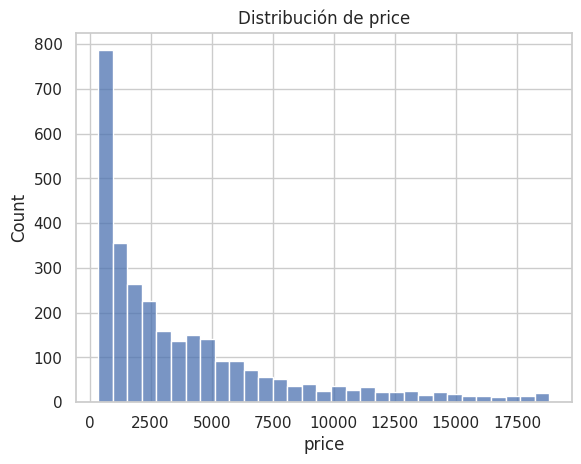

In [ ]:
#Distribucion de price
fig, ejes = plt.subplots()

sns.histplot(df_diam["price"], ax=ejes)
ejes.set_title("Distribución de price")

plt.show()

Podemos observar que la mayoria de los diamantes de este dataset ronda entre un precio de 500 y 5000 dolares aproximadamente.
Mientras que unos pocos diamantes cuestan mas de 7500 dolares.

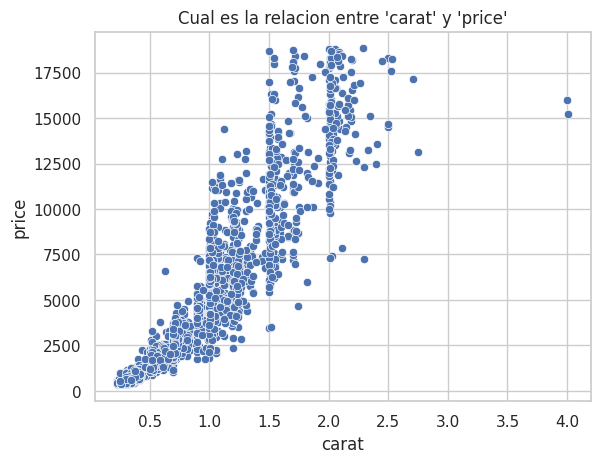

In [ ]:
#Relacion entre carat y price
fig, ejes = plt.subplots()

sns.scatterplot(data=df_diam, x="carat", y="price")
ejes.set_title("Cual es la relacion entre 'carat' y 'price'")

plt.show()

Existe una clara relacion positiva entre carat y price, a medida que va aumentando el peso del diamante, su precio aumenta exponencialmente, por eso la relacion no es del todo lineal, ya que como podemos ver es mas bien un aumento en curva.

Tambien se puede ver una aplia dispercion en los precios a medida que aumentan su peso, por ejemplo: podemos observar que un diamante que pesa 1,5 quilates puede costar entre 2750(aprox) y mas de 18000 dolares.

**1.2 · División y preprocesamiento.**
- Separá `X` (todo menos `price`) e `y` (`price`).
- Dividí en entrenamiento (80 %) y prueba (20 %).
- Armá un `ColumnTransformer` que estandarice las numéricas y aplique `OneHotEncoder` a `cut`, `color` y `clarity`.

In [ ]:
# Tu código aquí
# Pista: mirá el "Paso 1" y el "Paso 2" de la Parte 2.
# cols_num_d = [...]
# cols_cat_d = [...]

diam_X = df_diam[["carat", "cut", "color", "clarity", "depth", "table", "x", "y", "z"]]
diam_y = df_diam["price"]

#Divido datos de entrenamiento y prueba
X_ent, X_prueba, y_ent, y_prueba = train_test_split(
    diam_X, diam_y, test_size=0.2, random_state=SEMILLA
    )

print("Datos de entrenamiento:", X_ent.shape[0])
print("Datos de prueba:", X_prueba.shape[0])

Datos de entrenamiento: 2400
Datos de prueba: 600


In [ ]:
#Preprocesamos los datos
col_num = ["carat", "depth", "table", "x", "y", "z"]
col_cat = ["cut", "color", "clarity"]

#Definimos el proceso por el que pasara cada columnas
preprocesamiento = ColumnTransformer([
    ("num", Pipeline([
        ("escalar", StandardScaler())
    ]),col_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), col_cat) #Para que el codigo no se rompa si aparece una categoria nueva
])

preprocesamiento

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('escalar',
                                                  StandardScaler())]),
                                 ['carat', 'depth', 'table', 'x', 'y', 'z']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['cut', 'color', 'clarity'])])

**1.3 · Modelos de referencia.** Entrená un `DummyRegressor` y una `LinearRegression`, y guardá sus métricas (RMSE, MAE, R²) en una lista de resultados usando la función `evaluar_regresion` que ya definimos.

In [ ]:
# Tu código aquí
# Pista: resultados_diam = []  y luego resultados_diam.append(evaluar_regresion(...))
# Función para evaluar un modelo de regresión de forma ordenada
def rendimiento_modelo(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "RMSE_entrenamiento": root_mean_squared_error(y_ent, pred_ent),
        "RMSE_prueba": root_mean_squared_error(y_prueba, pred_prueba),
        "MAE_prueba": mean_absolute_error(y_prueba, pred_prueba),
        "R2_prueba": r2_score(y_prueba, pred_prueba),
    }

# Aquí iremos guardando los resultados de cada modelo para compararlos al final
resultados_diam = []

In [ ]:
#Modelo dummy
dummy_diam = DummyRegressor(strategy="mean")
dummy_diam.fit(X_ent[col_num], y_ent)
resultados_diam.append(rendimiento_modelo(dummy_diam, X_ent[col_num], y_ent, X_prueba[col_num], y_prueba, "Modelo Dummy"))

#Regresion Lineal
regresion_lineal = Pipeline([
    ("prep", preprocesamiento),
    ("modelo", LinearRegression())
])

regresion_lineal.fit(X_ent, y_ent)
resultados_diam.append(rendimiento_modelo(regresion_lineal, X_ent, y_ent, X_prueba, y_prueba, "Regresion Lineal"))

pd.DataFrame(resultados_diam)

,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Modelo Dummy,4040.451,4249.481,3220.319,-0.001
1,Regresion Lineal,1138.336,1106.483,730.659,0.932


El modelo dummy obtiene un r2 = 0, lo esperado en un modelo que predice el precio calculando su promedio, el mae indica que el modelo tiene un error de 3220 dolares en promedio en cada registro que intento predecir y el rmse eleva ese error al cuadrado, los promedia y luego saca la raiz, por ende es mas sensible a errores grandes.

El modelo de regresion lineal obtuvo un r2 = 0,93, osea que las predicciones puede explicar de una forma optima la variacion de precios.

El mae indica que el modelo tiene un promedio de error de 730 dolares en los registros que predijo.

El rmse es mayor que el mae esto nos indica que existen algunos errores grandes en las predicciones.
Tambien podemos concluir con que el modelo no presenta sobreajuste ya que la diferencia del rmse_entrenamiento y rmse_prueba no presenta una gran diferencia.

**1.4 · Primera red neuronal.** Entrená un `MLPRegressor` con `hidden_layer_sizes=(64, 32)` dentro de un `Pipeline`. Evaluá en entrenamiento y prueba. Graficá **real vs. predicho** y la **curva de pérdida**. ¿Le gana a la regresión lineal?

In [ ]:
# Tu código aquí
# Pista: Paso 4 y Paso 5 de la Parte 2.
modelo_neuronal = Pipeline([
    ("prep", preprocesamiento),
    ("mod_neuronal", MLPRegressor(
        hidden_layer_sizes=(64,32),
        activation="relu",
        max_iter=2000,
        random_state=SEMILLA
    ))
])

modelo_neuronal.fit(X_ent, y_ent)

#Cuantas epocas uso la red?
print("Epocas realizadas:", modelo_neuronal.named_steps["mod_neuronal"].n_iter_)
resultados_diam.append(rendimiento_modelo(modelo_neuronal, X_ent, y_ent, X_prueba, y_prueba, "MLP inicial (64, 32)"))
pd.DataFrame(resultados_diam)

Epocas realizadas: 2000


,modelo,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
0,Modelo Dummy,4040.451,4249.481,3220.319,-0.001
1,Regresion Lineal,1138.336,1106.483,730.659,0.932
2,"MLP inicial (64, 32)",587.467,595.227,333.803,0.980


Los resultados fueron bastante buenos en comparacion con los demas modelos, el modelo en comparacion con la regresion lineal paso de no explicar el 7% de la variacion de los precios a un 2%

Ademas podemos ver que las metricas que miden los errores muestran unos resultados ampliamente mejores.

El modelo neuronal se equivoca en promedio (mae) en 333 dolares a la hora de predecir el precio de los diamantes.

Y con el RMSE, en primera instancia podemos notar que no hay sobreajuste ya que los resulatados en las pruebas y en el entrenamiento es similar.
Ademas estos resultados indican que el modelo logro reducir ampliamente los errores grandes que presentaban los modelos anteriores.

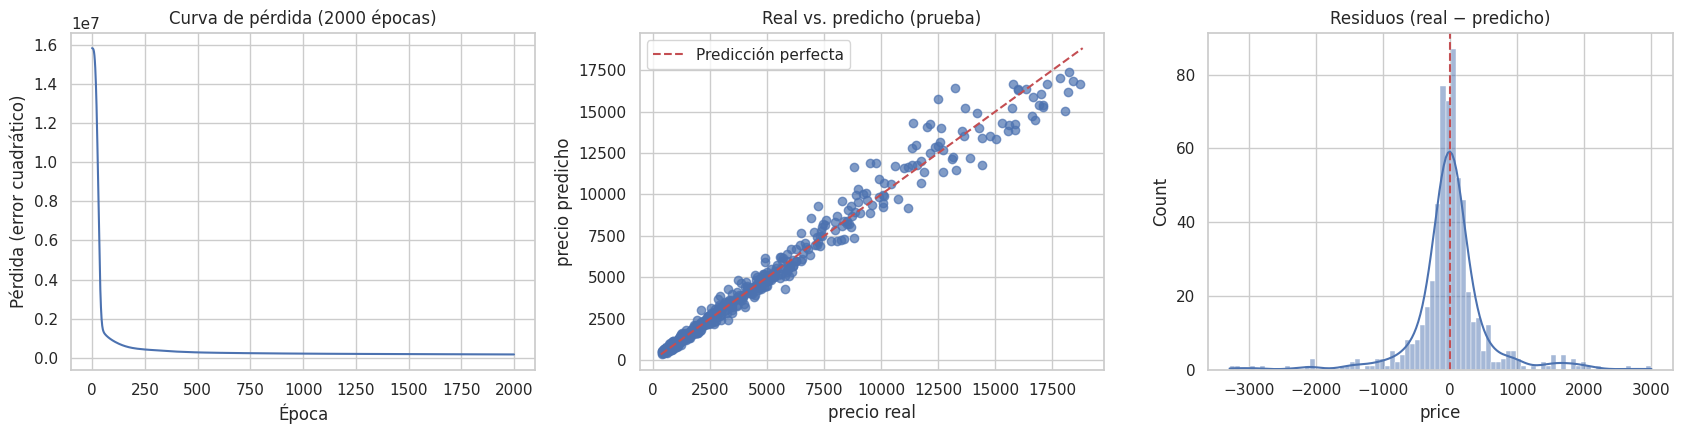

In [ ]:
red = modelo_neuronal.named_steps["mod_neuronal"]
pred_prueba = modelo_neuronal.predict(X_prueba)
residuos = y_prueba - pred_prueba

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

# 1) Curva de pérdida durante el entrenamiento
ejes[0].plot(red.loss_curve_)
ejes[0].set_title(f"Curva de pérdida ({red.n_iter_} épocas)")
ejes[0].set_xlabel("Época")
ejes[0].set_ylabel("Pérdida (error cuadrático)")

# 2) Real vs predicho
ejes[1].scatter(y_prueba, pred_prueba, alpha=0.7)
lim = [diam_y.min(), diam_y.max()]
ejes[1].plot(lim, lim, "r--", label="Predicción perfecta")
ejes[1].set_title("Real vs. predicho (prueba)")
ejes[1].set_xlabel("precio real")
ejes[1].set_ylabel("precio predicho")
ejes[1].legend()

# 3) Histograma de residuos
sns.histplot(residuos, kde=True, ax=ejes[2])
ejes[2].axvline(0, color="r", linestyle="--")
ejes[2].set_title("Residuos (real − predicho)")

plt.tight_layout()
plt.show()

En el primer grafico podemos observar que el modelo utilizo las 2000 epocas que habiamos definido como limite, el modelo aprendio la mayor parte entre las primeras 50 y 100 epocas, luego fue bajando el error de forma muy leve.

En el segundo grafico podemos ver como el modelo predice muchisimo mejor los diamantes con precio bajo, algo que ya habiamos supuesto al observar los valores de RMSE, osea que el modelo funcionaba peor prediciendo precios altos.
El modelo podria predecir peor estos diamantes ya que en el dataset pocos diamantes con precios altos.  

En el tercer grafico podemos ver que la mayoria de los errores que cometio el modelo al predecir el precio esta entre los -1000 y 1000 dolares, y los errores con valores mayores a esos son reducidos.



**1.5 · Ajuste de hiperparámetros.** Usá `GridSearchCV` o `RandomizedSearchCV` (a tu elección) con validación cruzada de 5 particiones para explorar al menos **3 hiperparámetros** (por ejemplo `hidden_layer_sizes`, `alpha`, `learning_rate_init`). Mostrá los 5 mejores resultados y evaluá el mejor modelo en el conjunto de prueba.

⏱️ *Cuidado con el tiempo de ejecución: empezá con una grilla chica.*

In [ ]:
# Tu código aquí
# Pista: Paso 8 y Paso 9 de la Parte 2 (o Paso 4 de la Parte 3 para RandomizedSearchCV).

valores_evaluar = {
    "mod_neuronal__hidden_layer_sizes": [(16,), (64,), (64, 32)],   # arquitecturas
    "mod_neuronal__alpha": [0.0001, 0.01, 1.0],                     # regularización
    "mod_neuronal__learning_rate_init": [0.001, 0.01],              # tamaño de paso
}

busqueda_val = GridSearchCV(
    estimator=modelo_neuronal,
    param_grid=valores_evaluar,
    cv=5, #Validacion cruzada de 5 particiones
    scoring="neg_root_mean_squared_error",
    verbose=1
)

busqueda_val.fit(X_ent, y_ent)

print("\nMejores hiperparámetros:")
print(busqueda_val.best_params_)
print(f"\nMejor RMSE en validación cruzada: {-busqueda_val.best_score_:.3f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits

Mejores hiperparámetros:
{'mod_neuronal__alpha': 0.0001, 'mod_neuronal__hidden_layer_sizes': (64, 32), 'mod_neuronal__learning_rate_init': 0.01}

Mejor RMSE en validación cruzada: 665.146


In [ ]:
#Mostrar los resultados graficamente
resultados = pd.DataFrame(busqueda_val.cv_results_)
resultados["RMSE_cv"] = -resultados["mean_test_score"]     # volvemos a un RMSE positivo

columnas = ["param_mod_neuronal__hidden_layer_sizes", "param_mod_neuronal__alpha",
            "param_mod_neuronal__learning_rate_init",
            "RMSE_cv", "std_test_score", "rank_test_score"]

resultados.sort_values("rank_test_score")[columnas].head(8)

,param_mod_neuronal__hidden_layer_sizes,param_mod_neuronal__alpha,param_mod_neuronal__learning_rate_init,RMSE_cv,std_test_score,rank_test_score
5,"(64, 32)",1.000e-04,0.010,665.146,64.481,1
16,"(64, 32)",1.000e+00,0.001,666.182,65.848,2
1,"(16,)",1.000e-04,0.010,667.890,59.407,3
7,"(16,)",1.000e-02,0.010,668.621,61.882,4
4,"(64, 32)",1.000e-04,0.001,669.342,57.926,5
10,"(64, 32)",1.000e-02,0.001,669.739,55.363,6
17,"(64, 32)",1.000e+00,0.010,670.154,54.288,7
11,"(64, 32)",1.000e-02,0.010,671.824,53.305,8


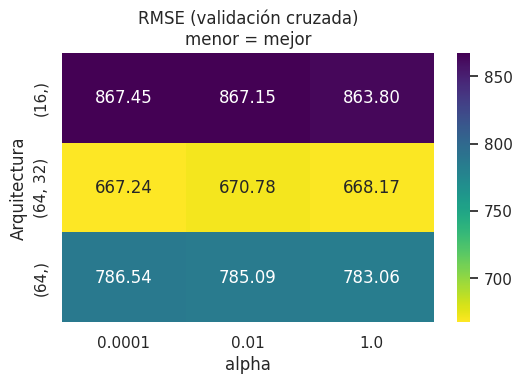

In [ ]:
resultados["arquitectura"] = resultados["param_mod_neuronal__hidden_layer_sizes"].astype(str)
tabla = resultados.pivot_table(index="arquitectura", columns="param_mod_neuronal__alpha", values="RMSE_cv", aggfunc="mean")

plt.figure(figsize=(6, 3.5))
sns.heatmap(tabla, annot=True, fmt=".2f", cmap="viridis_r")
plt.title("RMSE (validación cruzada)\nmenor = mejor")
plt.xlabel("alpha")
plt.ylabel("Arquitectura")
plt.show()

In [ ]:
mejor_reg = busqueda_val.best_estimator_

resultados_diam.append(rendimiento_modelo(mejor_reg, X_ent, y_ent, X_prueba, y_prueba, "MLP optimizado (GridSearch)"))

tabla_final_reg = pd.DataFrame(resultados_diam).set_index("modelo")
tabla_final_reg

,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
modelo,,,,
Modelo Dummy,4040.451,4249.481,3220.319,-0.001
Regresion Lineal,1138.336,1106.483,730.659,0.932
"MLP inicial (64, 32)",587.467,595.227,333.803,0.980
MLP optimizado (GridSearch),583.908,586.251,331.943,0.981


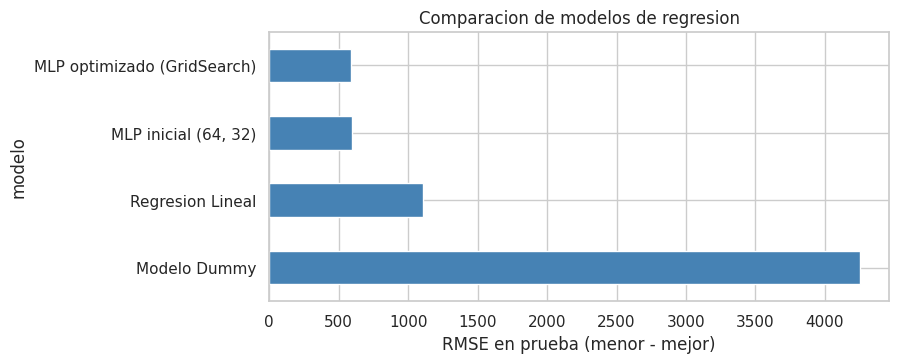

In [ ]:
tabla_final_reg["RMSE_prueba"].plot(kind="barh", figsize=(8, 3.5), color="steelblue")
plt.xlabel("RMSE en prueba (menor - mejor)")
plt.title("Comparacion de modelos de regresion")
plt.show()

Al analizar el modelo despues de correr el mismo variando sus hiperparametros llegamos a la conclusion de que la mejor configuracion para el mismo es de dos capas ocultas, una de 64 y otra de 32, un alpha de 0.01 y un learning_rate_init de 0.01.

El modelo optimizado obtiene menos valor de RMSE y MAE en comparacion con el modelo inicial, sin embargo, la mejora es muy pequeña por lo que podria deberse a la variabilidad propia del entrenamiento.



**1.6 · Interpretación.** Calculá la importancia por permutación del mejor modelo y graficala. ¿Qué variables son más importantes? ¿Coincide con lo que esperabas?

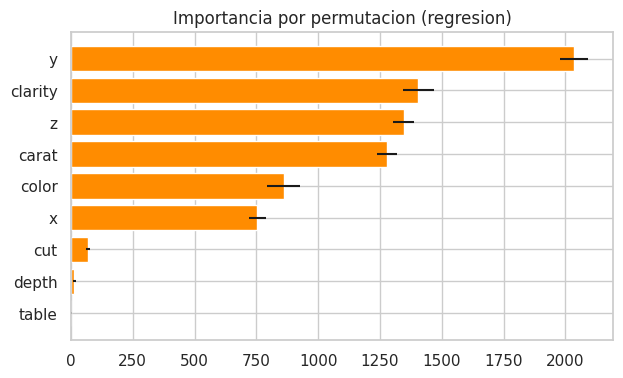

In [ ]:
# Tu código aquí
# Pista: Paso 10 de la Parte 2.
importancia = permutation_importance(
    mejor_reg, X_prueba, y_prueba,
    n_repeats = 20,
    scoring="neg_root_mean_squared_error",
    random_state=SEMILLA
)

imp = pd.DataFrame({
    "Variable": X_prueba.columns,
    "aumento_RMSE": importancia.importances_mean, #Cuanto empeora el RMSE al mezclar la variable
    "desvio": importancia.importances_std
}).sort_values("aumento_RMSE")

plt.figure(figsize=(7, 4))
plt.barh(imp["Variable"], imp["aumento_RMSE"], xerr=imp["desvio"], color="darkorange")
plt.title("Importancia por permutacion (regresion)")
plt.show()

**Tu respuesta (1.6):**

*(escribí acá tus conclusiones)*

Cada barra muestra cuanto empeora el RMSE si mezclamos al azar esa columna. Por ende podemos observar que las variables mas influyentes son las relacionados al tamaño, sobre todo y.

Tambien podemos observar que la claridad y el color del diamantes son muy influyente en las predicciones del modelo, ya que estas definen la calidad del diamante.

**1.7 · Desafío extra: el precio en escala logarítmica.**

El precio de los diamantes es muy asimétrico (muchos baratos, pocos carísimos). Una técnica habitual es **predecir el logaritmo del precio** y luego volver a la escala original. En `scikit-learn` esto se hace fácil con `TransformedTargetRegressor`:

```python
from sklearn.compose import TransformedTargetRegressor

modelo_log = TransformedTargetRegressor(
    regressor=tu_pipeline_con_mlp,   # el Pipeline que ya armaste
    func=np.log1p,                   # transforma y antes de entrenar
    inverse_func=np.expm1            # revierte la transformación al predecir
)
```

Entrená este modelo, evaluá en prueba y compará con el anterior. ¿Mejoró? ¿Por qué creés que pasa esto?

In [ ]:
# Tu código aquí
from sklearn.compose import TransformedTargetRegressor

modelo_log = TransformedTargetRegressor(
    regressor=modelo_neuronal,   # el Pipeline que ya armaste
    func=np.log1p,                   # transforma y antes de entrenar
    inverse_func=np.expm1            # revierte la transformación al predecir
)

modelo_log.fit(X_ent, y_ent)

resultados_diam.append(rendimiento_modelo(modelo_log, X_ent, y_ent, X_prueba, y_prueba, "MLP Logaritmico"))
pd.DataFrame(resultados_diam).set_index("modelo")

,RMSE_entrenamiento,RMSE_prueba,MAE_prueba,R2_prueba
modelo,,,,
Modelo Dummy,4040.451,4249.481,3220.319,-0.001
Regresion Lineal,1138.336,1106.483,730.659,0.932
"MLP inicial (64, 32)",587.467,595.227,333.803,0.980
MLP optimizado (GridSearch),583.908,586.251,331.943,0.981
MLP Logaritmico,821.743,798.858,429.612,0.965


**Tu respuesta (1.7):**

*(escribí acá tus conclusiones)*

El modelo no mejoro al escalar el precio de forma logaritmica, esto se debe ya que la red neurona ya podia aprender de manera inicial la relacion entre las variables y el precio, ademas al pasar las predicciones de logaritmo a dolares, los errores se agranden en los diamantes caros, los errores mas influyentes en el RMSE.

---
## Actividad 4 · reflexión final 💭

Respondé brevemente (2-4 líneas cada una) con tus propias palabras:

1. ¿Por qué es **obligatorio** escalar las variables antes de entrenar una red neuronal? ¿Qué observaste en la demostración?
2. ¿Por qué ajustamos hiperparámetros con **validación cruzada sobre el entrenamiento** y no directamente mirando el conjunto de prueba?
3. En el Paso 6 vimos que distintas semillas dan resultados distintos. ¿Cómo influye esto en la forma en que deberíamos **reportar** el rendimiento de una red neuronal?

**Tus respuestas:**

1. Los modelos de redes neuronales son muy sensibles a los cambios de escalas entre variables numericas, por ejemplo el ancho de la cara superior plana de un diamante con el diametro de uno de sus lados, por ende si no escalamos, el modelo aprende mal. En el paso 3 podemos observar que si no escalamos el modelo es inestable y presenta desde R2 = 0.891 hasta R2 = -72.231
2. Ajustamos los hiperparametros sobre el conjunto de entrenamiento para que no haya una fuga de datos y el modelo aprenda los resultados que tiene que predecir viendo el conjunto de prueba, algo que haria que el modelo no sea realista ya que va a obtener mejores resultados.
3. Debemos realizar pruebas en diferentes seeds y ver como se comporta el modelos, si su rendimiento en las diferentes pruebas no presenta cambios abruptos, podemos presentar un modelo confiable.
Se debe presentar un promedio y el desvio de los resultados en distintas semillas

---
# 🏁 ¡Felicitaciones!

Completaste una introducción completa al uso de redes neuronales en `scikit-learn`. Recordá la idea central:

> **Una red neuronal no es magia: es un modelo más que hay que preparar bien, evaluar con honestidad y comparar contra alternativas simples.**

 📚 Para seguir explorando
- Documentación de redes neuronales en scikit-learn: <https://scikit-learn.org/stable/modules/neural_networks_supervised.html>
- Guía de validación cruzada: <https://scikit-learn.org/stable/modules/cross_validation.html>
- Ajuste de hiperparámetros: <https://scikit-learn.org/stable/modules/grid_search.html>
- Importancia por permutación: <https://scikit-learn.org/stable/modules/permutation_importance.html>
- Datasets usados: [Auto MPG (UCI)](https://archive.ics.uci.edu/dataset/9/auto+mpg), [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/), y los datasets de ejemplo de [seaborn-data](https://github.com/mwaskom/seaborn-data).